# Healthcare Data Analytics Project

## Project Overview

An end-to-end healthcare data analytics project using Python,
SQL Server and data visualisation.

## Objectives
- Analyse hospital admissions.
- Clean and validate healthcare data.
- Identify revenue trends.
- Evaluate hospital performance.
- Analyse patient demographics.

## Tools Used
- Microsoft SQL Server
- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

# 1. Data Loading and Initial Inspection

## Objective
Load the hospital dataset into Python and understand its structure, dimensions and data types.

## Initial Inspection
The dataset contains 55,500 hospital admission records and 15 columns.

The initial inspection focuses on:
- Understanding dataset dimensions.
- Identifying column names and data types.
- Reviewing statistical summaries.
- Checking missing values and duplicate records.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("healthcare_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


# 2. Data Profiling and Data Cleaning

## Objective
Assess the quality of the raw healthcare dataset and identify data inconsistencies before performing analysis.

## Data Quality Checks

The following checks were performed:

- Missing value identification.
- Duplicate record detection.
- Negative billing value identification.
- Patient age validation.
- Admission and discharge date validation.

## Key Findings

| Data Quality Check | Result |
|---|---:|
| Total records | 55,500 |
| Missing values | 0 |
| Duplicate records | 534 |
| Original negative billing records | 108 |
| Negative billing records after duplicate removal | 106 |
| Invalid patient ages | 0 |
| Invalid discharge dates | 0 |

## Data Cleaning Methodology

1. Removed 534 duplicate records.
2. Identified 106 negative billing records in the deduplicated dataset.
3. Replaced negative billing values with NULL rather than treating them as valid revenue.
4. Created a separate cleaned billing column for subsequent analysis.

## Final Dataset

- Original records: 55,500
- Records after duplicate removal: 54,966
- Remaining negative billing values: 0
- Missing values in cleaned billing column: 106

The cleaned dataset was used for subsequent healthcare performance and revenue analysis.

In [4]:
df.shape

(55500, 15)

In [5]:
df.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  str    
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  str    
 3   Blood Type          55500 non-null  str    
 4   Medical Condition   55500 non-null  str    
 5   Date of Admission   55500 non-null  str    
 6   Doctor              55500 non-null  str    
 7   Hospital            55500 non-null  str    
 8   Insurance Provider  55500 non-null  str    
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  str    
 12  Discharge Date      55500 non-null  str    
 13  Medication          55500 non-null  str    
 14  Test Results        55500 non-null  str    
dtypes: float64(1), int64(2), str(12)
memory usage: 12.3 MB


In [7]:
df.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


In [8]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(534)

In [10]:
df[df["Billing Amount"] < 0].shape[0]

108

In [11]:
df[(df["Age"] < 0) | (df["Age"] > 120)].shape[0]

0

In [12]:
df_clean = df.copy()

print("Working copy created successfully!")

Working copy created successfully!


In [13]:
df_clean = df_clean.drop_duplicates()

print("Records after removing duplicates:", len(df_clean))

Records after removing duplicates: 54966


In [14]:
df_clean[df_clean["Billing Amount"] < 0].shape[0]

106

In [15]:
df_clean["Billing Amount Cleaned"] = np.where(
    df_clean["Billing Amount"] < 0,
    np.nan,
    df_clean["Billing Amount"]
)

In [16]:
print("Original records:", len(df))
print("Cleaned records:", len(df_clean))

print("Negative billing values remaining:",
      (df_clean["Billing Amount Cleaned"] < 0).sum())

print("Missing values in cleaned billing:",
      df_clean["Billing Amount Cleaned"].isnull().sum())

Original records: 55500
Cleaned records: 54966
Negative billing values remaining: 0
Missing values in cleaned billing: 106


# 3. Healthcare KPIs and Business Analysis

## Objective
Develop key performance indicators (KPIs) to evaluate hospital admissions, revenue generation, patient demographics and operational performance.

## Overall Healthcare KPIs

The following metrics were calculated using the cleaned dataset:

| KPI | Result |
|---|---:|
| Total Admissions | 54,966 |
| Distinct Hospitals | 39,876 |
| Distinct Doctors | 40,341 |
| Average Patient Age | 51.54 years |
| Total Revenue | 1,404,121,601.24 |
| Average Billing | 25,594.63 |
| Average Length of Stay | 15.50 days |

## Business Analysis Areas

The analysis examined:

1. **Hospital Performance:** Admissions, total revenue and average billing by hospital.
2. **Medical Conditions:** Patient volume, revenue and average billing across medical conditions.
3. **Insurance Provider Analysis:** Admissions, revenue and hospital coverage by insurance provider.
4. **Admission Type:** Comparison of elective, emergency and urgent admissions.
5. **Patient Demographics:** Revenue and patient distribution by age group and gender.
6. **Monthly Trends:** Monthly admissions, revenue, month-over-month changes and cumulative revenue.

These KPIs provide a foundation for understanding healthcare operations and identifying patterns in hospital performance.

In [17]:
condition_revenue = (
    df_clean.groupby("Medical Condition")
    ["Billing Amount Cleaned"]
    .sum()
    .sort_values(ascending=False)
)

condition_revenue

Medical Condition
Diabetes        2.364947e+08
Obesity         2.360171e+08
Arthritis       2.351735e+08
Hypertension    2.333869e+08
Asthma          2.331462e+08
Cancer          2.299032e+08
Name: Billing Amount Cleaned, dtype: float64

In [18]:
condition_admissions = (
    df_clean["Medical Condition"]
    .value_counts()
)

condition_admissions

Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

In [19]:
average_billing = (
    df_clean.groupby("Medical Condition")
    ["Billing Amount Cleaned"]
    .mean()
    .sort_values(ascending=False)
)

average_billing

Medical Condition
Obesity         25859.215373
Diabetes        25714.326349
Asthma          25685.385020
Hypertension    25559.844868
Arthritis       25542.898356
Cancer          25205.924207
Name: Billing Amount Cleaned, dtype: float64

In [20]:
condition_revenue = (
    df_clean.groupby("Medical Condition")["Billing Amount Cleaned"]
    .sum()
    .sort_values(ascending=False)
)

condition_revenue

Medical Condition
Diabetes        2.364947e+08
Obesity         2.360171e+08
Arthritis       2.351735e+08
Hypertension    2.333869e+08
Asthma          2.331462e+08
Cancer          2.299032e+08
Name: Billing Amount Cleaned, dtype: float64

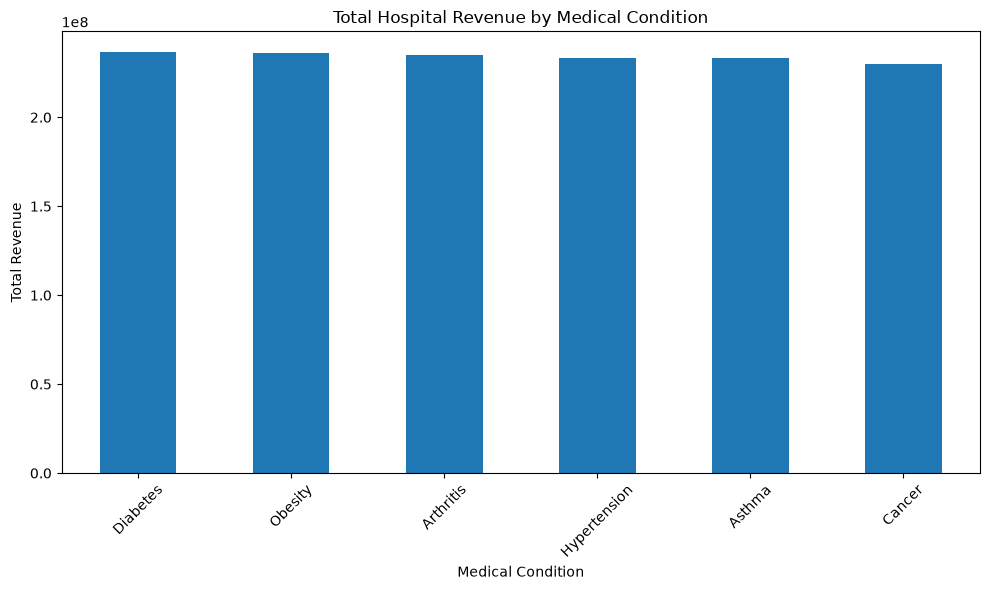

In [21]:
plt.figure(figsize=(10, 6))

condition_revenue.plot(kind="bar")

plt.title("Total Hospital Revenue by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [22]:
df_clean["Date of Admission"] = pd.to_datetime(
    df_clean["Date of Admission"]
)

# 4. Advanced SQL and Python Analysis

## Objective
Apply advanced analytical techniques to identify revenue patterns, admission trends and changes in hospital performance over time.

## Advanced SQL Techniques

The following SQL concepts were implemented:

- Common Table Expressions (CTEs)
- RANK() and DENSE_RANK()
- LAG() for previous-month comparisons
- Month-over-Month growth calculations
- Cumulative revenue using window functions
- Revenue contribution percentages

## Python Analytical Techniques

Python was used to perform:

- Monthly admission trend analysis.
- Month-over-Month growth calculations using shift().
- Identification of highest and lowest admission periods.
- Revenue analysis by medical condition.
- Hospital performance ranking.
- Insurance provider comparison.
- Age-group segmentation.
- Gender-based analysis.

## Key Findings

- August 2020 recorded the highest monthly admissions: 1,003.
- June 2019 recorded the highest MoM growth: 32.79%.
- February 2022 recorded the largest monthly decline: 19.58%.
- Diabetes generated the highest revenue among medical conditions.
- Patients above 65 represented the largest age group.
- Elective admissions generated the highest revenue among admission types.

## Visualisation

Matplotlib was used to create visualisations covering:
- Revenue by medical condition.
- Monthly hospital admissions.
- Month-over-Month admission growth.
- Hospital revenue comparisons.
- Insurance provider performance.
- Age-group and gender distribution.

In [23]:
monthly_admissions = (
    df_clean
    .groupby(
        df_clean["Date of Admission"].dt.to_period("M")
    )
    .size()
)

monthly_admissions.head(10)

Date of Admission
2019-05    677
2019-06    899
2019-07    951
2019-08    985
2019-09    924
2019-10    993
2019-11    950
2019-12    921
2020-01    942
2020-02    868
Freq: M, dtype: int64

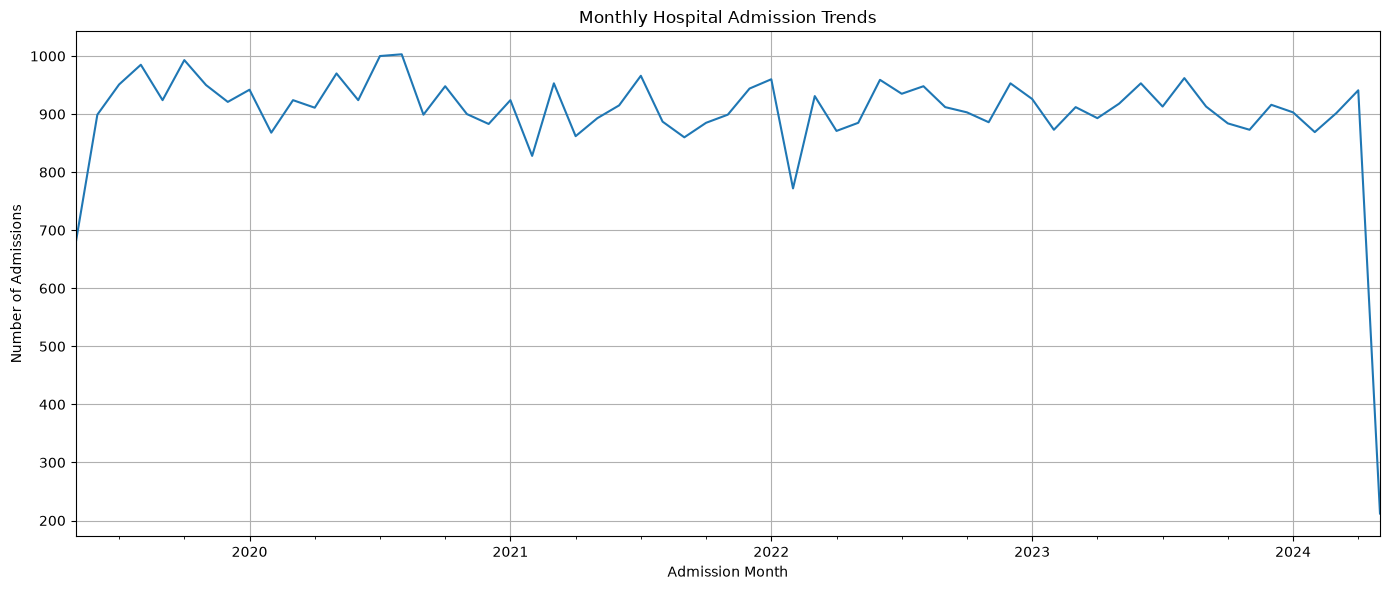

In [24]:
plt.figure(figsize=(14, 6))

monthly_admissions.plot(kind="line")

plt.title("Monthly Hospital Admission Trends")
plt.xlabel("Admission Month")
plt.ylabel("Number of Admissions")

plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
monthly_df = monthly_admissions.reset_index()

monthly_df.columns = ["Admission_Month", "Total_Admissions"]

monthly_df.head()

,Admission_Month,Total_Admissions
0,2019-05,677
1,2019-06,899
2,2019-07,951
3,2019-08,985
4,2019-09,924


In [26]:
monthly_df["Previous_Month_Admissions"] = (
    monthly_df["Total_Admissions"].shift(1)
)

monthly_df.head(10)

,Admission_Month,Total_Admissions,Previous_Month_Admissions
0,2019-05,677,NaN
1,2019-06,899,677.0
2,2019-07,951,899.0
3,2019-08,985,951.0
4,2019-09,924,985.0
5,2019-10,993,924.0
6,2019-11,950,993.0
7,2019-12,921,950.0
8,2020-01,942,921.0
9,2020-02,868,942.0


In [27]:
monthly_df["Admission_Difference"] = (
    monthly_df["Total_Admissions"] -
    monthly_df["Previous_Month_Admissions"]
)

In [28]:
monthly_df["Growth_Percentage"] = (
    monthly_df["Admission_Difference"] /
    monthly_df["Previous_Month_Admissions"]
) * 100

In [29]:
monthly_df.head(15)

,Admission_Month,Total_Admissions,Previous_Month_Admissions,Admission_Difference,Growth_Percentage
0,2019-05,677,NaN,NaN,NaN
1,2019-06,899,677.0,222.0,32.791728
2,2019-07,951,899.0,52.0,5.784205
3,2019-08,985,951.0,34.0,3.575184
4,2019-09,924,985.0,-61.0,-6.192893
5,2019-10,993,924.0,69.0,7.467532
6,2019-11,950,993.0,-43.0,-4.330312
7,2019-12,921,950.0,-29.0,-3.052632
8,2020-01,942,921.0,21.0,2.280130
9,2020-02,868,942.0,-74.0,-7.855626


In [30]:
monthly_df.loc[
    monthly_df["Total_Admissions"].idxmax()
]

Admission_Month              2020-08
Total_Admissions                1003
Previous_Month_Admissions     1000.0
Admission_Difference             3.0
Growth_Percentage                0.3
Name: 15, dtype: object

In [31]:
monthly_df.loc[
    monthly_df["Total_Admissions"].idxmin()
]

Admission_Month                2024-05
Total_Admissions                   212
Previous_Month_Admissions        941.0
Admission_Difference            -729.0
Growth_Percentage           -77.470776
Name: 60, dtype: object

In [32]:
monthly_df.loc[
    monthly_df["Growth_Percentage"].idxmax()
]

Admission_Month                2019-06
Total_Admissions                   899
Previous_Month_Admissions        677.0
Admission_Difference             222.0
Growth_Percentage            32.791728
Name: 1, dtype: object

In [33]:
monthly_df.loc[
    monthly_df["Growth_Percentage"].idxmin()
]

Admission_Month                2024-05
Total_Admissions                   212
Previous_Month_Admissions        941.0
Admission_Difference            -729.0
Growth_Percentage           -77.470776
Name: 60, dtype: object

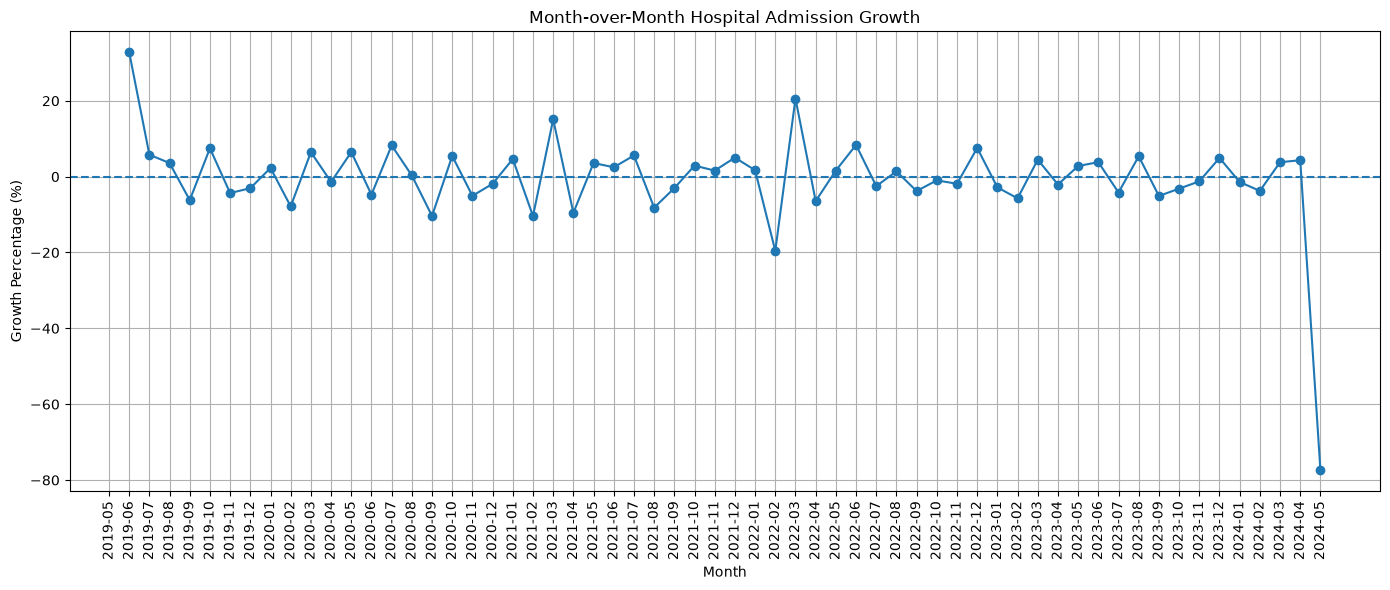

In [34]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_df["Admission_Month"].astype(str),
    monthly_df["Growth_Percentage"],
    marker="o"
)

plt.axhline(y=0, linestyle="--")

plt.title("Month-over-Month Hospital Admission Growth")
plt.xlabel("Month")
plt.ylabel("Growth Percentage (%)")

plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [35]:
monthly_complete = monthly_df[
    monthly_df["Admission_Month"] < "2024-05"
].copy()

In [36]:
monthly_complete.loc[
    monthly_complete["Total_Admissions"].idxmax()
]

Admission_Month              2020-08
Total_Admissions                1003
Previous_Month_Admissions     1000.0
Admission_Difference             3.0
Growth_Percentage                0.3
Name: 15, dtype: object

In [37]:
monthly_complete.loc[
    monthly_complete["Total_Admissions"].idxmin()
]

Admission_Month              2019-05
Total_Admissions                 677
Previous_Month_Admissions        NaN
Admission_Difference             NaN
Growth_Percentage                NaN
Name: 0, dtype: object

In [38]:
monthly_complete.loc[
    monthly_complete["Growth_Percentage"].idxmax()
]

Admission_Month                2019-06
Total_Admissions                   899
Previous_Month_Admissions        677.0
Admission_Difference             222.0
Growth_Percentage            32.791728
Name: 1, dtype: object

In [39]:
monthly_complete.loc[
    monthly_complete["Growth_Percentage"].idxmin()
]

Admission_Month                2022-02
Total_Admissions                   772
Previous_Month_Admissions        960.0
Admission_Difference            -188.0
Growth_Percentage           -19.583333
Name: 33, dtype: object

In [40]:
hospital_analysis = (
    df_clean.groupby("Hospital")
    .agg(
        Total_Admissions=("Name", "count"),
        Total_Revenue=("Billing Amount Cleaned", "sum"),
        Average_Billing=("Billing Amount Cleaned", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)

hospital_analysis.head(10)

,Total_Admissions,Total_Revenue,Average_Billing
Hospital,,,
Johnson PLC,37,1.081477e+06,29229.116540
LLC Smith,44,1.030190e+06,23413.406187
Smith PLC,36,1.029424e+06,28595.123587
Ltd Smith,39,1.003366e+06,25727.321223
Smith Ltd,37,9.700359e+05,26217.185560
Johnson Inc,34,9.369313e+05,29279.102308
Group Smith,32,9.029758e+05,28217.993358
Inc Brown,27,8.779613e+05,32517.085733
LLC Johnson,30,8.164384e+05,27214.611790


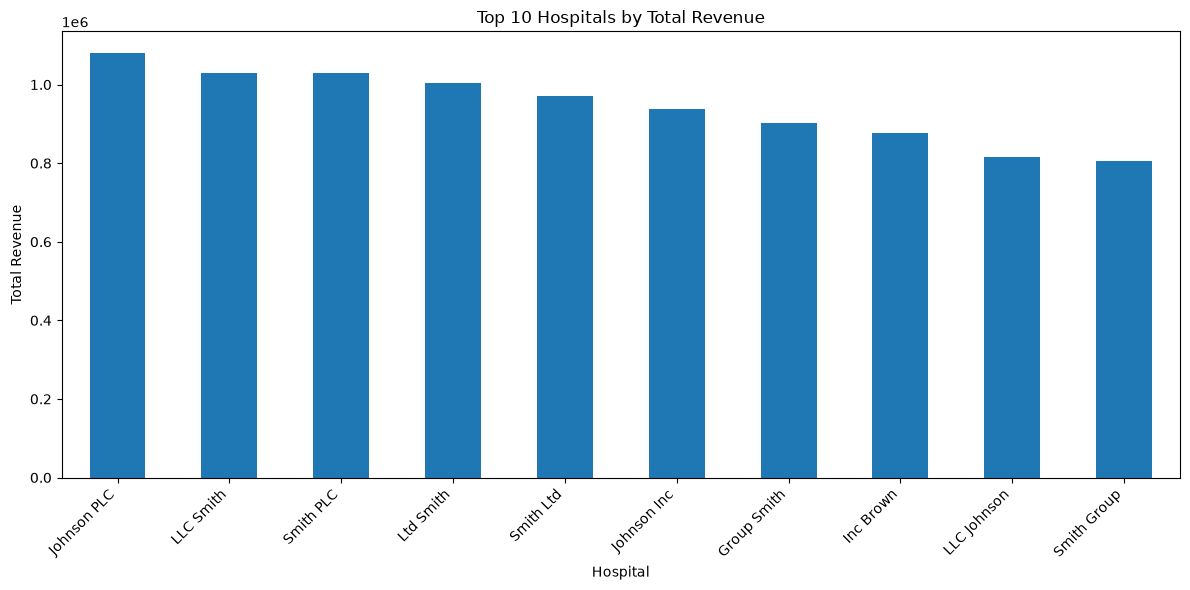

In [41]:
top_hospitals = hospital_analysis.head(10)

plt.figure(figsize=(12, 6))

top_hospitals["Total_Revenue"].plot(kind="bar")

plt.title("Top 10 Hospitals by Total Revenue")
plt.xlabel("Hospital")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [42]:
insurance_analysis = (
    df_clean.groupby("Insurance Provider")
    .agg(
        Total_Admissions=("Name", "count"),
        Total_Revenue=("Billing Amount Cleaned", "sum"),
        Average_Billing=("Billing Amount Cleaned", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)

insurance_analysis

,Total_Admissions,Total_Revenue,Average_Billing
Insurance Provider,,,
Cigna,11139,2.843465e+08,25582.227724
Medicare,11039,2.829212e+08,25678.087847
Blue Cross,10952,2.804167e+08,25639.269835
UnitedHealthcare,11014,2.799205e+08,25458.893302
Aetna,10822,2.765167e+08,25615.260975


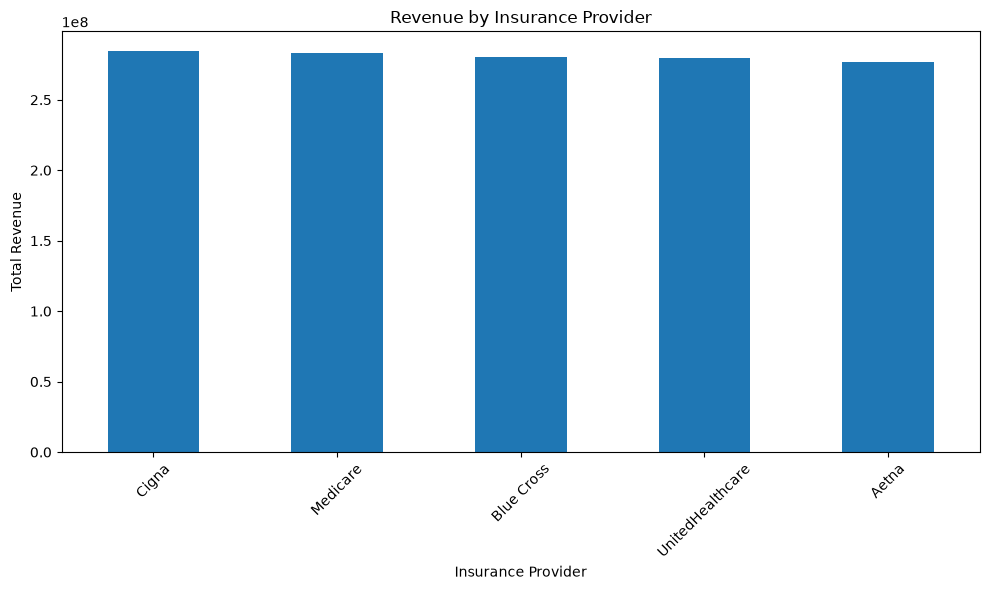

In [43]:
plt.figure(figsize=(10, 6))

insurance_analysis["Total_Revenue"].plot(kind="bar")

plt.title("Revenue by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

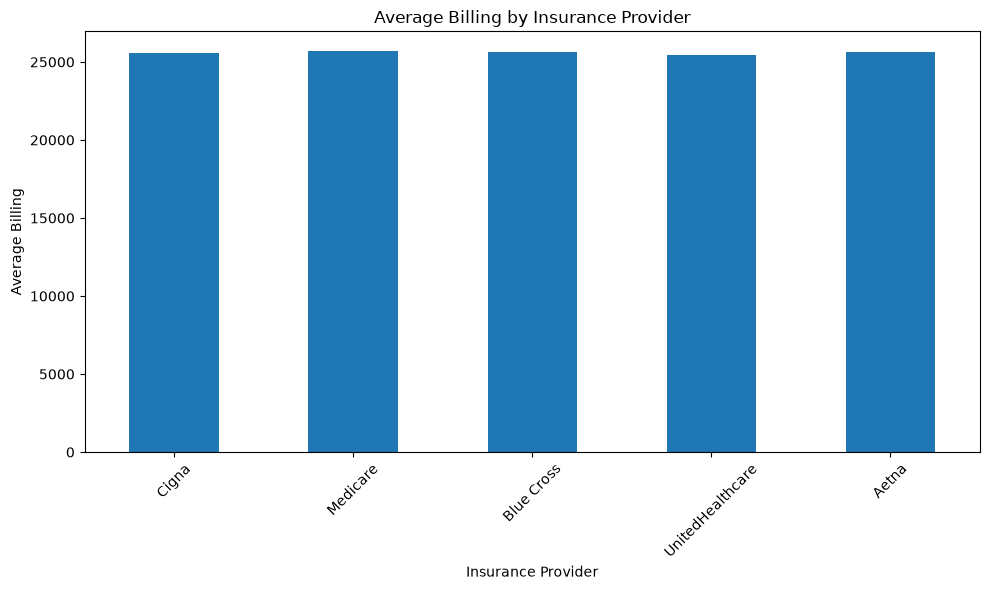

In [44]:
plt.figure(figsize=(10, 6))

insurance_analysis["Average_Billing"].plot(kind="bar")

plt.title("Average Billing by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Average Billing")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:

insurance_analysis.round(2)

,Total_Admissions,Total_Revenue,Average_Billing
Insurance Provider,,,
Cigna,11139,2.843465e+08,25582.23
Medicare,11039,2.829212e+08,25678.09
Blue Cross,10952,2.804167e+08,25639.27
UnitedHealthcare,11014,2.799205e+08,25458.89
Aetna,10822,2.765167e+08,25615.26


In [46]:
admission_analysis = (
    df_clean.groupby("Admission Type")
    .agg(
        Total_Admissions=("Name", "count"),
        Total_Revenue=("Billing Amount Cleaned", "sum"),
        Average_Billing=("Billing Amount Cleaned", "mean")
    )
)

admission_analysis.round(2)

,Total_Admissions,Total_Revenue,Average_Billing
Admission Type,,,
Elective,18473,4.731550e+08,25663.34
Emergency,18102,4.617090e+08,25551.13
Urgent,18391,4.692576e+08,25568.44


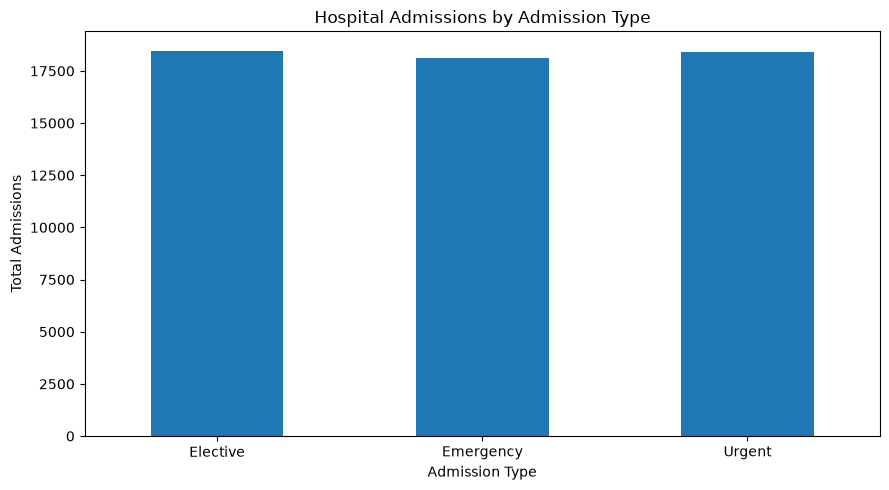

In [47]:
plt.figure(figsize=(9, 5))

admission_analysis["Total_Admissions"].plot(kind="bar")

plt.title("Hospital Admissions by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Total Admissions")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

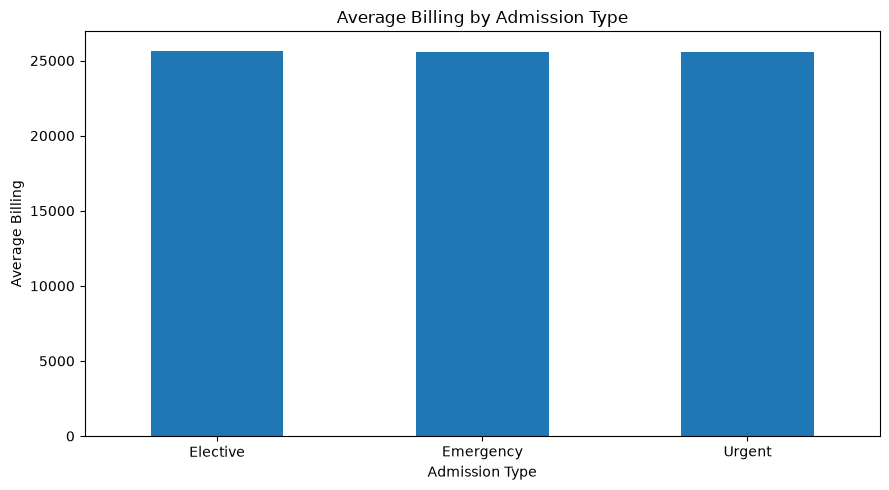

In [48]:
plt.figure(figsize=(9, 5))

admission_analysis["Average_Billing"].plot(kind="bar")

plt.title("Average Billing by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Average Billing")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [49]:
admission_analysis.round(2)

,Total_Admissions,Total_Revenue,Average_Billing
Admission Type,,,
Elective,18473,4.731550e+08,25663.34
Emergency,18102,4.617090e+08,25551.13
Urgent,18391,4.692576e+08,25568.44


In [50]:
df_clean["Age_Group"] = pd.cut(
    df_clean["Age"],
    bins=[0, 18, 35, 50, 65, 100],
    labels=["0-18", "19-35", "36-50", "51-65", "Above 65"]
)

df_clean[["Age", "Age_Group"]].head(10)

,Age,Age_Group
0,30,19-35
1,62,51-65
2,76,Above 65
3,28,19-35
4,43,36-50
5,36,36-50
6,21,19-35
7,20,19-35
8,82,Above 65
9,58,51-65


In [51]:
age_analysis = (
    df_clean.groupby("Age_Group", observed=False)
    .agg(
        Total_Patients=("Name", "count"),
        Total_Revenue=("Billing Amount Cleaned", "sum"),
        Average_Billing=("Billing Amount Cleaned", "mean")
    )
)

age_analysis.round(2)

,Total_Patients,Total_Revenue,Average_Billing
Age_Group,,,
0-18,886,2.369729e+07,26776.60
19-35,13519,3.450146e+08,25573.69
36-50,12167,3.104273e+08,25564.30
51-65,12298,3.156281e+08,25708.90
Above 65,16096,4.093543e+08,25482.71


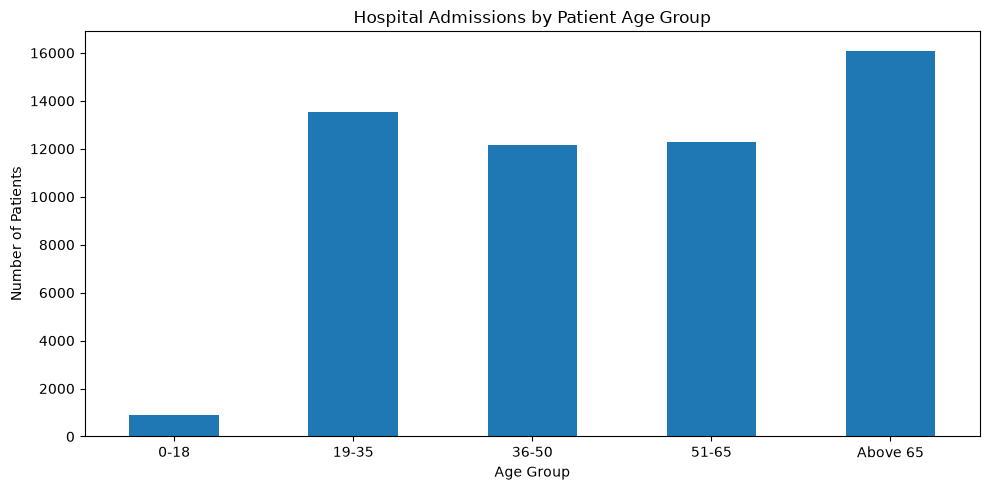

In [52]:
plt.figure(figsize=(10, 5))

age_analysis["Total_Patients"].plot(kind="bar")

plt.title("Hospital Admissions by Patient Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

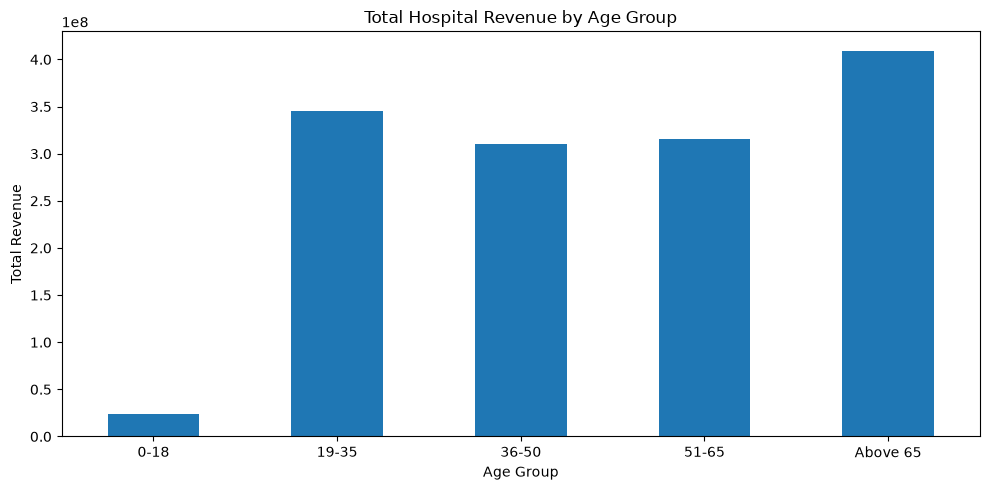

In [53]:
plt.figure(figsize=(10, 5))

age_analysis["Total_Revenue"].plot(kind="bar")

plt.title("Total Hospital Revenue by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Revenue")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [54]:
age_analysis.round(2)

,Total_Patients,Total_Revenue,Average_Billing
Age_Group,,,
0-18,886,2.369729e+07,26776.60
19-35,13519,3.450146e+08,25573.69
36-50,12167,3.104273e+08,25564.30
51-65,12298,3.156281e+08,25708.90
Above 65,16096,4.093543e+08,25482.71


In [55]:
age_analysis["Total_Patients"]

Age_Group
0-18          886
19-35       13519
36-50       12167
51-65       12298
Above 65    16096
Name: Total_Patients, dtype: int64

In [56]:
gender_analysis = (
    df_clean.groupby("Gender")
    .agg(
        Total_Patients=("Name", "count"),
        Total_Revenue=("Billing Amount Cleaned", "sum"),
        Average_Billing=("Billing Amount Cleaned", "mean")
    )
)

gender_analysis.round(2)

,Total_Patients,Total_Revenue,Average_Billing
Gender,,,
Female,27470,6.998010e+08,25529.94
Male,27496,7.043206e+08,25659.24


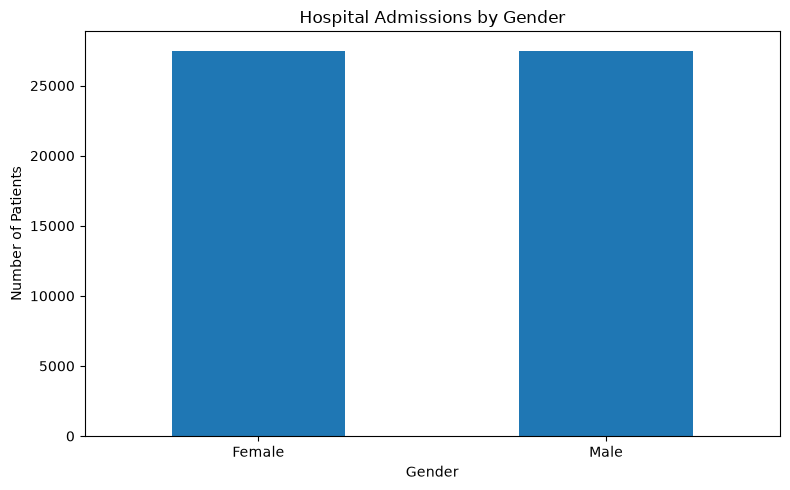

In [57]:
plt.figure(figsize=(8, 5))

gender_analysis["Total_Patients"].plot(kind="bar")

plt.title("Hospital Admissions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

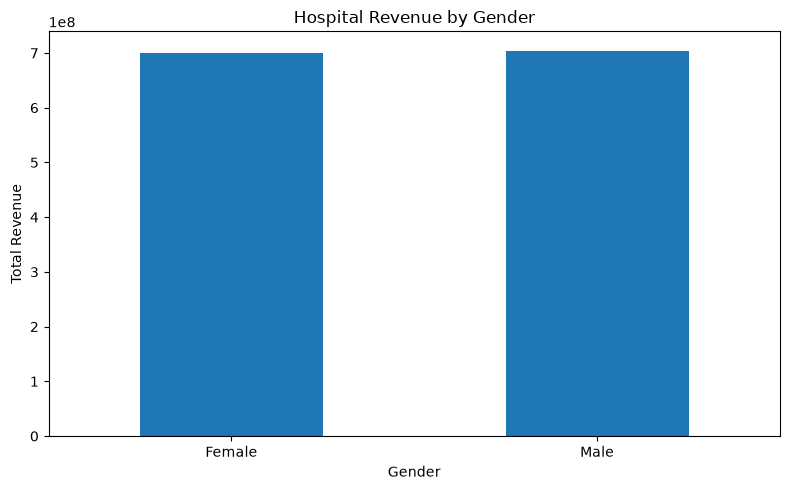

In [58]:
plt.figure(figsize=(8, 5))

gender_analysis["Total_Revenue"].plot(kind="bar")

plt.title("Hospital Revenue by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Revenue")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [59]:
gender_analysis.round(2)

,Total_Patients,Total_Revenue,Average_Billing
Gender,,,
Female,27470,6.998010e+08,25529.94
Male,27496,7.043206e+08,25659.24


In [60]:
hospital_performance = (
    df_clean.groupby("Hospital")
    .agg(
        Total_Admissions=("Name", "count"),
        Total_Revenue=("Billing Amount Cleaned", "sum"),
        Average_Billing=("Billing Amount Cleaned", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)

hospital_performance.head(10).round(2)

,Total_Admissions,Total_Revenue,Average_Billing
Hospital,,,
Johnson PLC,37,1081477.31,29229.12
LLC Smith,44,1030189.87,23413.41
Smith PLC,36,1029424.45,28595.12
Ltd Smith,39,1003365.53,25727.32
Smith Ltd,37,970035.87,26217.19
Johnson Inc,34,936931.27,29279.10
Group Smith,32,902975.79,28217.99
Inc Brown,27,877961.31,32517.09
LLC Johnson,30,816438.35,27214.61


In [61]:
hospital_performance.sort_values(
    "Total_Admissions", ascending=False
).head(10)

,Total_Admissions,Total_Revenue,Average_Billing
Hospital,,,
LLC Smith,44,1.030190e+06,23413.406187
Ltd Smith,39,1.003366e+06,25727.321223
Johnson PLC,37,1.081477e+06,29229.116540
Smith Ltd,37,9.700359e+05,26217.185560
Smith PLC,36,1.029424e+06,28595.123587
Smith Group,36,8.067679e+05,23728.468529
Johnson Inc,34,9.369313e+05,29279.102308
Smith Inc,33,7.722565e+05,23401.711987
Group Smith,32,9.029758e+05,28217.993358


In [62]:
hospital_performance.sort_values(
    "Average_Billing", ascending=False
).head(10).round(2)

,Total_Admissions,Total_Revenue,Average_Billing
Hospital,,,
Hernandez-Morton,2,104746.06,52373.03
Walker-Garcia,2,104340.07,52170.04
Ruiz-Anthony,1,52154.24,52154.24
George-Gonzalez,1,52102.24,52102.24
Rocha-Carter,1,52092.67,52092.67
"Briggs Walker Martinez, and",1,52024.73,52024.73
"and Small Stephens Harrington,",2,103951.94,51975.97
Clark-Espinoza,1,51848.20,51848.20
"Pierce and Miller James,",1,51722.12,51722.12


In [63]:
high_volume_hospitals = hospital_performance[
    hospital_performance["Total_Admissions"] >= 30
]

high_volume_hospitals.sort_values(
    "Total_Revenue", ascending=False
).head(10).round(2)

,Total_Admissions,Total_Revenue,Average_Billing
Hospital,,,
Johnson PLC,37,1081477.31,29229.12
LLC Smith,44,1030189.87,23413.41
Smith PLC,36,1029424.45,28595.12
Ltd Smith,39,1003365.53,25727.32
Smith Ltd,37,970035.87,26217.19
Johnson Inc,34,936931.27,29279.10
Group Smith,32,902975.79,28217.99
LLC Johnson,30,816438.35,27214.61
Smith Group,36,806767.93,23728.47


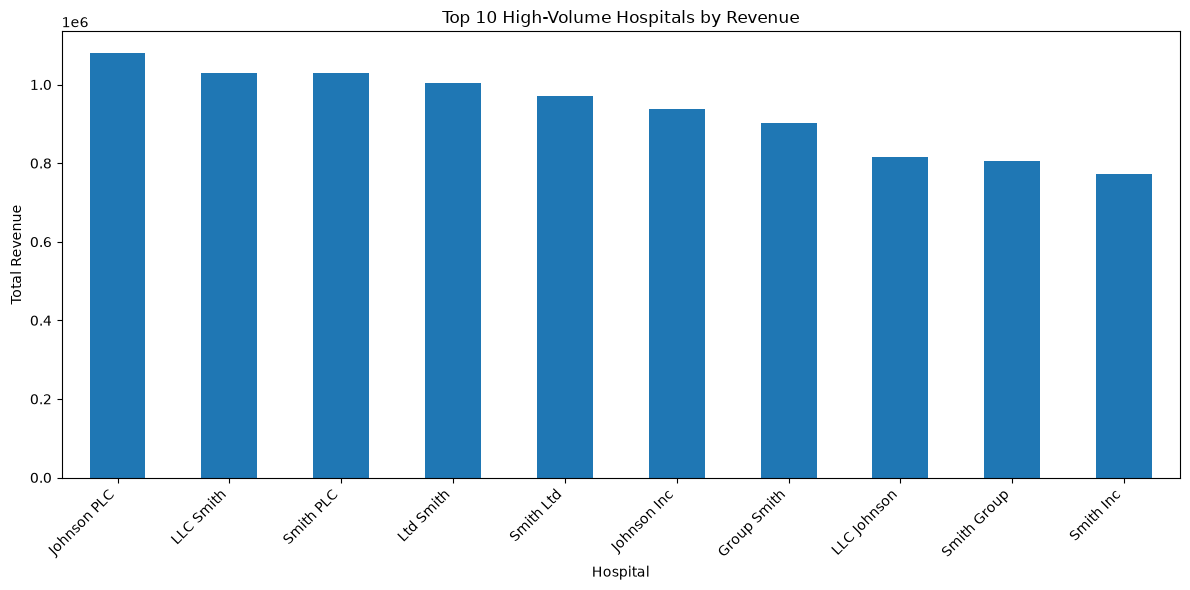

In [64]:
top_hospitals = high_volume_hospitals.sort_values(
    "Total_Revenue", ascending=False
).head(10)

plt.figure(figsize=(12, 6))

top_hospitals["Total_Revenue"].plot(kind="bar")

plt.title("Top 10 High-Volume Hospitals by Revenue")
plt.xlabel("Hospital")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [65]:
df_clean.to_csv(
    "cleaned_healthcare_dataset.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [66]:
import os

print(os.path.abspath("cleaned_healthcare_dataset.csv"))
print(os.path.exists("cleaned_healthcare_dataset.csv"))

C:\Users\Vinayak Gujjar\Healthcare analysis\cleaned_healthcare_dataset.csv
True


# 5. Project Conclusion

## Key Takeaways

- Analysed 55,500 hospital admission records and identified 534 duplicate records.
- Cleaned the dataset by removing duplicates and flagging invalid negative billing values.
- Identified key healthcare KPIs, including total admissions, revenue, average patient age, and length of stay.
- Compared medical conditions, insurance providers, admission types, age groups, and hospitals.
- Used SQL and Python to perform data cleaning, analysis, and visualisation.

## Business Insights

- Patients above 65 years represented the largest age group by admission volume.
- Diabetes generated the highest total revenue among the medical conditions.
- Cigna recorded the highest admission volume among insurance providers.
- Elective admissions had the highest total admission volume.
- Hospital-level comparisons highlighted differences in admission volume and revenue.

## Limitations

- The dataset does not specify the currency of billing amounts.
- Hospital and doctor names should be treated as dataset identifiers, not verified real-world entities.
- The dataset appears synthetic; findings should not be generalised to actual hospital operations.

## Skills Demonstrated

SQL | Python | Pandas | NumPy | Data Cleaning | Exploratory Data Analysis | Data Visualisation | Healthcare Analytics